# Diabetes Prediction using Logistic Regression
## The project aims to predict whether a person has diabetes or not.

**Dataset:** Pima Indians Diabetes Database (Kaggle)  
**Algorithm:** Logistic Regression  
**Problem Type:** Binary Classification

The dataset and prediction problem are different from the original Loan Approval practical. The overall workflow and evaluation measures are kept similar.

## Loading Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

In [ ]:
# Load the Pima Indians Diabetes dataset directly from a public URL to bypass Kaggle API authentication
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# The dataset does not have a header row, so we define the column names manually
column_names = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

data = pd.read_csv(url, names=column_names)
df = data.copy()
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Understanding Data

In [ ]:
print("Dataset shape:", df.shape)
df.isnull().sum()

Dataset shape: (768, 9)


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Outliers Detection

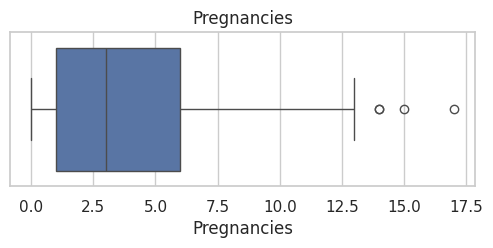

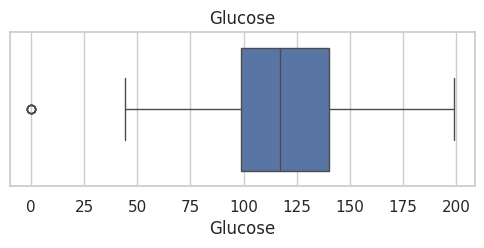

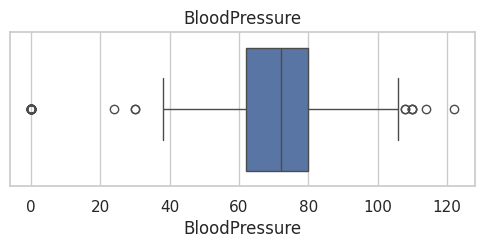

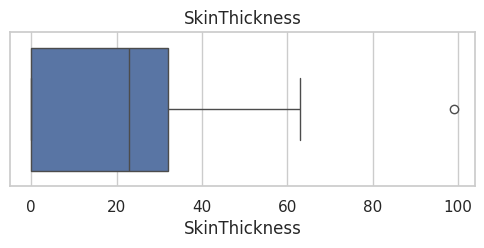

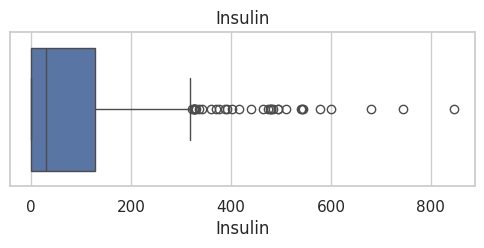

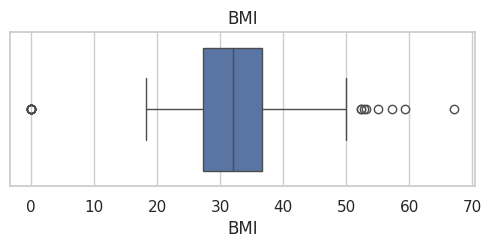

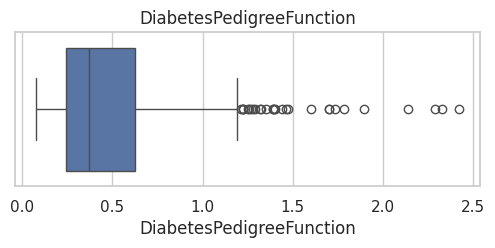

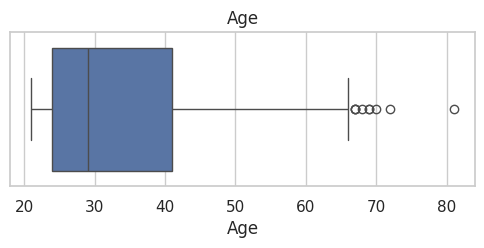

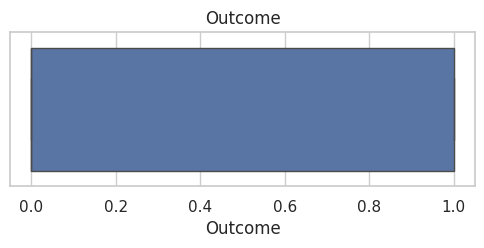

In [ ]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns

for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

### Handling Invalid Zero Values
In this dataset, zero is not a realistic value for some medical measurements. We replace those zero entries with the median of the respective column. The target column `Outcome` is not changed.

In [ ]:
zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]

for col in zero_columns:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## EDA

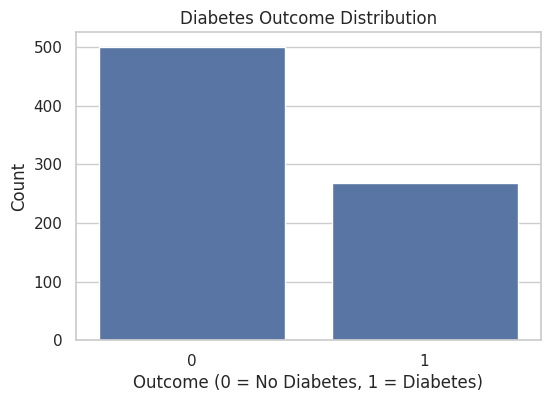

In [ ]:
# Distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

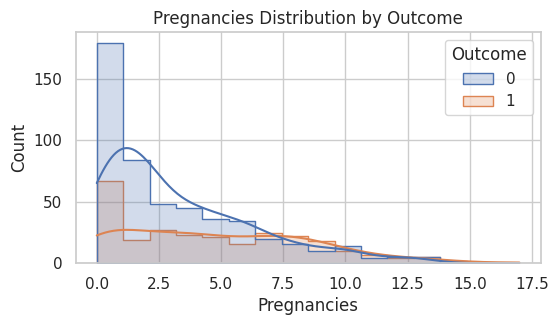

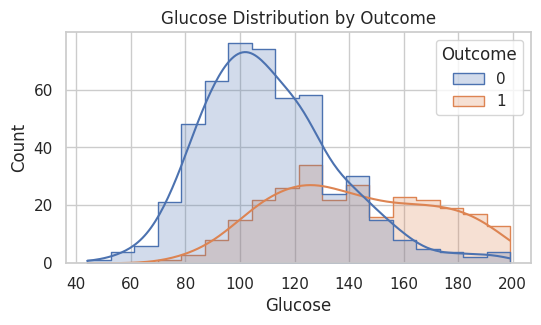

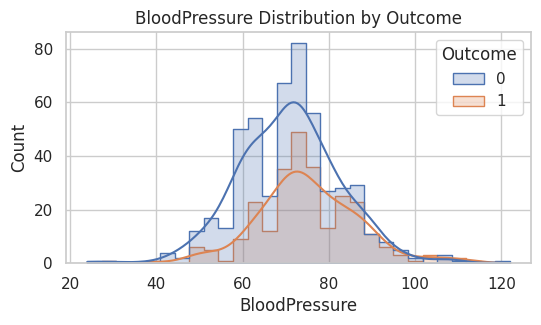

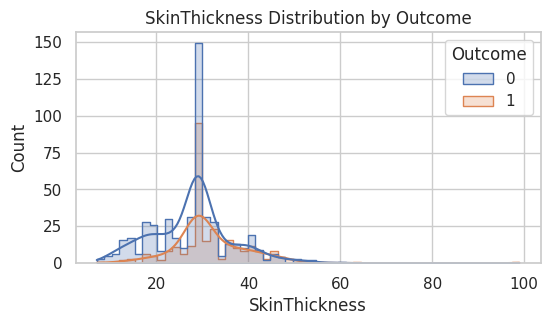

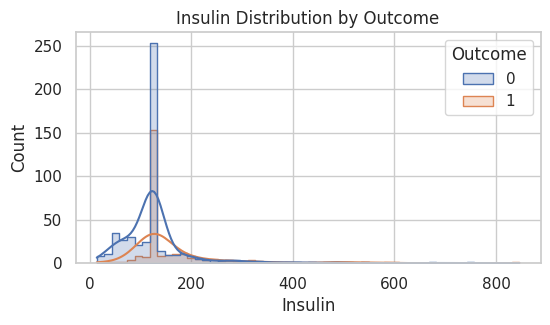

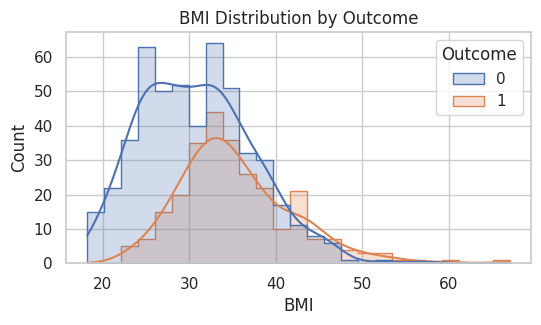

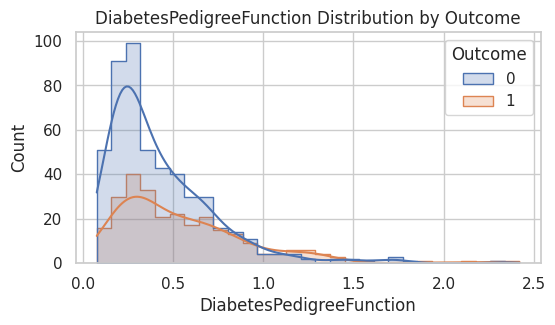

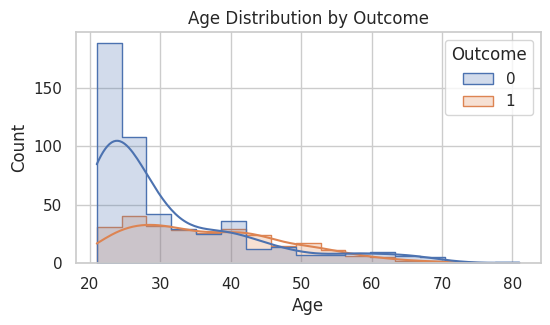

In [ ]:
# Distribution of numerical features by outcome
feature_cols = [col for col in df.columns if col != "Outcome"]

for col in feature_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, element="step")
    plt.title(f"{col} Distribution by Outcome")
    plt.show()

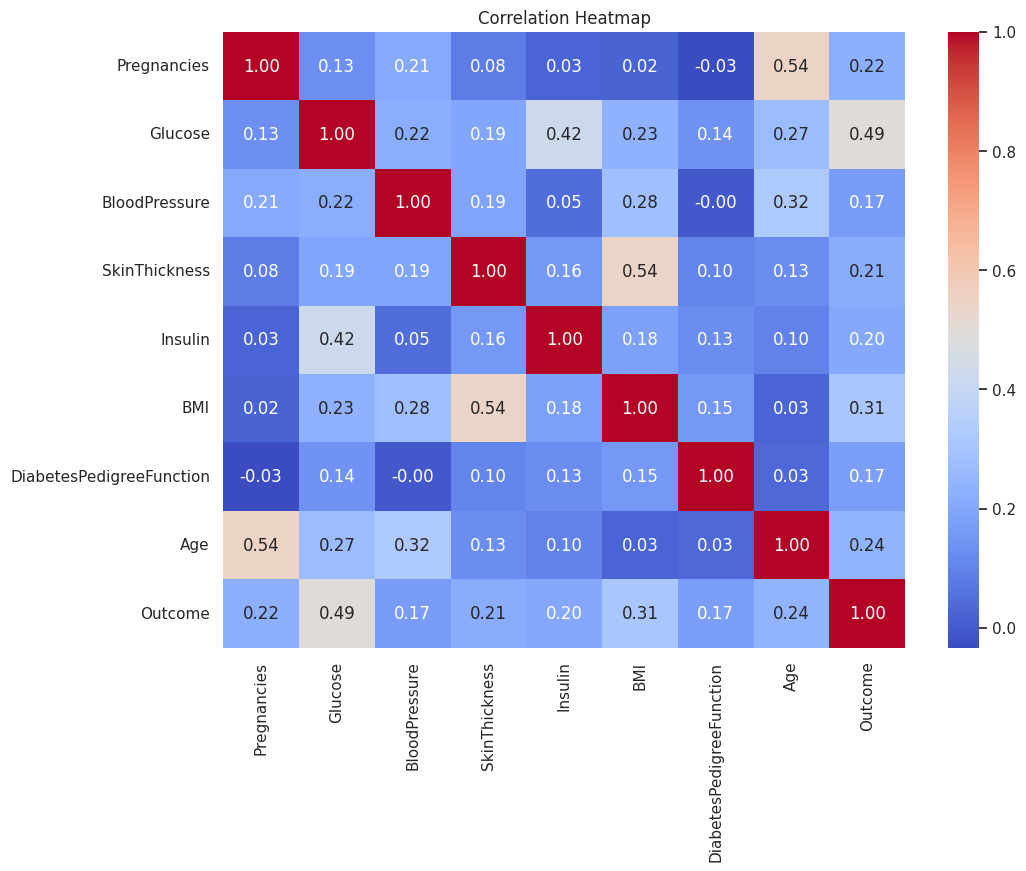

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Split and Scaling

In [ ]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (576, 8)
Testing data: (192, 8)


In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


## Model Training

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

print("Logistic Regression model training completed.")

Logistic Regression model training completed.


## Model Evaluation

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score

y_pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred, zero_division=0))
print("Recall :", recall_score(y_test, y_pred, zero_division=0))

Accuracy : 0.7291666666666666
Precision : 0.6363636363636364
Recall : 0.5223880597014925


## Graphical Representation of Confusion Matrix

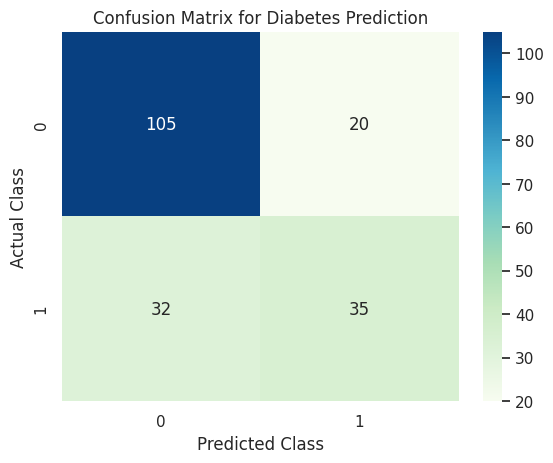

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='GnBu')
plt.title('Confusion Matrix for Diabetes Prediction')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

## Conclusion

In this practical, the Pima Indians Diabetes dataset from Kaggle was used to predict the diabetes outcome. Data understanding, outlier inspection, handling of invalid zero values, exploratory data analysis, train-test splitting, and feature scaling were performed.

A Logistic Regression model was trained and evaluated using **Accuracy, Precision, and Recall**. The confusion matrix was used for graphical evaluation. The final performance should be described using the actual metric values displayed after running the notebook.